Used DenseNet121 on our small dataset

In [1]:
import zipfile
zip_ref = zipfile.ZipFile("/Users/sudharsank/AIML/datasets/heros-dataset.zip", 'r')
zip_ref.extractall()
zip_ref.close()

In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [3]:
data_path='/Users/sudharsank/AIML/deep-learning/CNN/Hero-Multiclass-project.ipynb/heros/train'

In [4]:
train_datagen=ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    brightness_range=(0.5,1.5),
)

train=train_datagen.flow_from_directory(
    data_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

Found 207 images belonging to 3 classes.


In [5]:
test_datagen=ImageDataGenerator(rescale=1./255)

test=test_datagen.flow_from_directory(
    "/Users/sudharsank/AIML/deep-learning/CNN/Hero-Multiclass-project.ipynb/heros/test",
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 11 images belonging to 3 classes.


In [6]:
print(f"Number of images: {train.n}")
print(f"Image shape: {train.image_shape}")
print(f"Number of classes: {train.num_classes}")

Number of images: 207
Image shape: (224, 224, 3)
Number of classes: 3


In [7]:
model=Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)),
    MaxPooling2D(2,2),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128,(3,3),activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128,(3,3),activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.15),
    Dense(256,activation='relu'),
    Dropout(0.15),
    Dense(3,activation='softmax')
])

/Users/sudharsank/AIML/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     9,437,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,810,627 (37.42 MB)

 Trainable params: 9,810,627 (37.42 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history=model.fit(train,validation_data=test,epochs=7)

Epoch 1/7
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 614ms/step - accuracy: 0.4879 - loss: 0.9720 - val_accuracy: 0.5455 - val_loss: 0.9054
Epoch 2/7
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 648ms/step - accuracy: 0.5217 - loss: 0.9151 - val_accuracy: 0.5455 - val_loss: 0.8987
Epoch 3/7
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 979ms/step - accuracy: 0.4928 - loss: 0.9234 - val_accuracy: 0.5455 - val_loss: 0.8730
Epoch 4/7
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 947ms/step - accuracy: 0.5072 - loss: 0.9171 - val_accuracy: 0.5455 - val_loss: 0.8363
Epoch 5/7
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 756ms/step - accuracy: 0.5121 - loss: 0.8827 - val_accuracy: 0.6364 - val_loss: 0.9123
Epoch 6/7
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 685ms/step - accuracy: 0.5749 - loss: 0.9088 - val_accuracy: 0.6364 - val_loss: 0.8758
Epoch 7/7
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 559ms/step - accuracy: 0.5894 - loss: 0.8834 - val_accuracy: 0.6364 - val_loss: 0.8022


In [10]:
import matplotlib.pyplot as plt

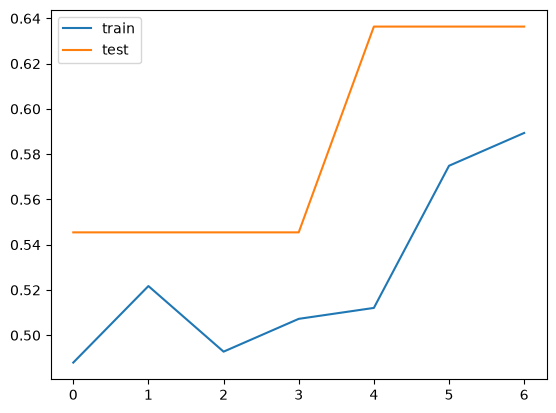

In [11]:
plt.plot(history.history['accuracy'],label='train')
plt.plot(history.history['val_accuracy'],label='test')
plt.legend()

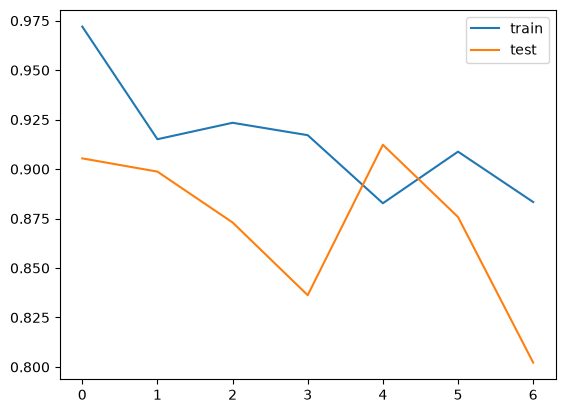

In [12]:
plt.plot(history.history['loss'],label='train')
plt.plot(history.history['val_loss'],label='test')
plt.legend()

In [12]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

train_dir = "/Users/sudharsank/AIML/deep-learning/CNN/Hero-Multiclass-project.ipynb/heros/train"
test_dir = "/Users/sudharsank/AIML/deep-learning/CNN/Hero-Multiclass-project.ipynb/heros/test"

# Balance the minority class ('allu arjun': 18 images vs 137 / 102) via training-only oversampling
rows = []
for cls in sorted(os.listdir(train_dir)):
    cls_dir = os.path.join(train_dir, cls)
    if not os.path.isdir(cls_dir):
        continue
    repeat = 6 if cls == "allu arjun" else 1
    for fname in sorted(os.listdir(cls_dir)):
        fpath = os.path.join(cls_dir, fname)
        for _ in range(repeat):
            rows.append({"filename": fpath, "class": cls})

train_df = pd.DataFrame(rows)

# Use DenseNet121's expected ImageNet normalization (no augmentation on test)
dn_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=(0.85, 1.15),
    fill_mode="nearest",
)
dn_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

dn_train = dn_train_datagen.flow_from_dataframe(
    train_df,
    x_col="filename",
    y_col="class",
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=True,
    seed=42,
)
dn_test = dn_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=False,
)
print("Class indices:", dn_train.class_indices)

Found 347 validated image filenames belonging to 3 classes.
Found 57 images belonging to 3 classes.
Class indices: {'allu arjun': 0, 'prabhas': 1, 'sharukh': 2}


In [13]:
base = DenseNet121(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    pooling="avg",
    name="densenet121",
)
# Stage 1: Freeze pretrained backbone so random head gradients do not corrupt ImageNet features
base.trainable = False

inputs = Input(shape=(224, 224, 3))
x = base(inputs, training=False)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
x = Dense(256, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
outputs = Dense(len(dn_train.class_indices), activation="softmax")(x)

model = Model(inputs, outputs, name="densenet121_heros")
model.summary()

Model: "densenet121_heros"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 1024)           │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)  

In [14]:
# Stage 1: Train classification head (feature extraction)
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop_1 = EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
)
reduce_lr_1 = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1
)

history_stage1 = model.fit(
    dn_train,
    validation_data=dn_test,
    epochs=25,
    callbacks=[early_stop_1, reduce_lr_1],
    verbose=2,
)

Epoch 1/25
22/22 - 16s - 740ms/step - accuracy: 0.4841 - loss: 1.3509 - val_accuracy: 0.5614 - val_loss: 0.8702 - learning_rate: 0.0010
Epoch 2/25
22/22 - 10s - 436ms/step - accuracy: 0.7464 - loss: 0.6896 - val_accuracy: 0.6667 - val_loss: 0.7336 - learning_rate: 0.0010
Epoch 3/25
22/22 - 10s - 461ms/step - accuracy: 0.8213 - loss: 0.5355 - val_accuracy: 0.6667 - val_loss: 0.8254 - learning_rate: 0.0010
Epoch 4/25
22/22 - 10s - 467ms/step - accuracy: 0.8329 - loss: 0.4550 - val_accuracy: 0.7018 - val_loss: 0.7439 - learning_rate: 0.0010
Epoch 5/25
22/22 - 10s - 458ms/step - accuracy: 0.8098 - loss: 0.5049 - val_accuracy: 0.7368 - val_loss: 0.6899 - learning_rate: 0.0010
Epoch 6/25
22/22 - 10s - 449ms/step - accuracy: 0.8213 - loss: 0.4156 - val_accuracy: 0.7368 - val_loss: 0.7801 - learning_rate: 0.0010
Epoch 7/25
22/22 - 10s - 451ms/step - accuracy: 0.8501 - loss: 0.3931 - val_accuracy: 0.7193 - val_loss: 0.8005 - learning_rate: 0.0010
Epoch 8/25

Epoch 8: ReduceLROnPlateau reducing 

In [15]:
# Stage 2: Fine-tune top DenseNet block (conv5_block*) while keeping BatchNorm layers frozen
base.trainable = True
unfreeze = False
for layer in base.layers:
    if layer.name.startswith("conv5_block"):
        unfreeze = True
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = unfreeze

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop_2 = EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
)
reduce_lr_2 = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
)

history_stage2 = model.fit(
    dn_train,
    validation_data=dn_test,
    epochs=25,
    callbacks=[early_stop_2, reduce_lr_2],
    verbose=2,
)

Epoch 1/25
22/22 - 19s - 853ms/step - accuracy: 0.8213 - loss: 0.4454 - val_accuracy: 0.7193 - val_loss: 0.7763 - learning_rate: 1.0000e-04
Epoch 2/25
22/22 - 11s - 483ms/step - accuracy: 0.8501 - loss: 0.4228 - val_accuracy: 0.7719 - val_loss: 0.7397 - learning_rate: 1.0000e-04
Epoch 3/25
22/22 - 11s - 512ms/step - accuracy: 0.8991 - loss: 0.2691 - val_accuracy: 0.7544 - val_loss: 0.7640 - learning_rate: 1.0000e-04
Epoch 4/25
22/22 - 14s - 617ms/step - accuracy: 0.9078 - loss: 0.2289 - val_accuracy: 0.7368 - val_loss: 0.7587 - learning_rate: 1.0000e-04
Epoch 5/25
22/22 - 13s - 611ms/step - accuracy: 0.8963 - loss: 0.2422 - val_accuracy: 0.7719 - val_loss: 0.6883 - learning_rate: 1.0000e-04
Epoch 6/25
22/22 - 13s - 608ms/step - accuracy: 0.9251 - loss: 0.2073 - val_accuracy: 0.8421 - val_loss: 0.5956 - learning_rate: 1.0000e-04
Epoch 7/25
22/22 - 14s - 624ms/step - accuracy: 0.9164 - loss: 0.1887 - val_accuracy: 0.8421 - val_loss: 0.5686 - learning_rate: 1.0000e-04
Epoch 8/25
22/22 - 1

In [16]:
test_loss, test_acc = model.evaluate(dn_test, verbose=0)
print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

from sklearn.metrics import classification_report, confusion_matrix
probs = model.predict(dn_test, verbose=0)
preds = np.argmax(probs, axis=1)
target_names = [k for k, _ in sorted(dn_test.class_indices.items(), key=lambda kv: kv[1])]
print("\nClassification Report:")
print(classification_report(dn_test.classes, preds, target_names=target_names))
print("Confusion Matrix:")
print(confusion_matrix(dn_test.classes, preds))

Final Test Loss: 0.5686
Final Test Accuracy: 0.8421 (84.21%)

Classification Report:
              precision    recall  f1-score   support

  allu arjun       1.00      0.43      0.60         7
     prabhas       0.85      0.93      0.89        30
     sharukh       0.81      0.85      0.83        20

    accuracy                           0.84        57
   macro avg       0.89      0.74      0.77        57
weighted avg       0.85      0.84      0.83        57

Confusion Matrix:
[[ 3  2  2]
 [ 0 28  2]
 [ 0  3 17]]


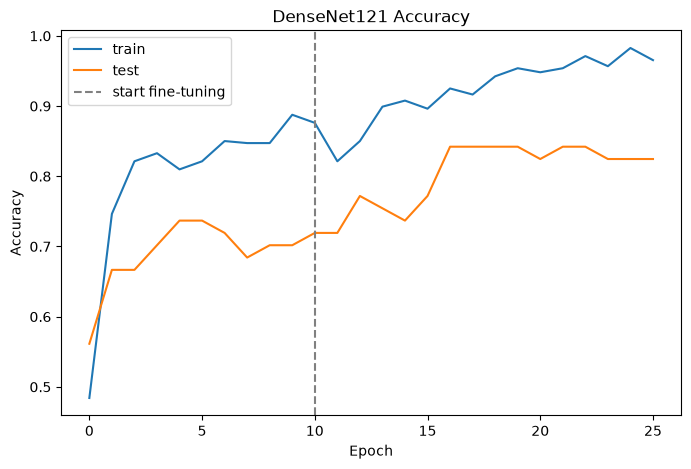

In [17]:
import matplotlib.pyplot as plt

acc = history_stage1.history["accuracy"] + history_stage2.history["accuracy"]
val_acc = history_stage1.history["val_accuracy"] + history_stage2.history["val_accuracy"]
stage1_len = len(history_stage1.history["accuracy"])

plt.figure(figsize=(8, 5))
plt.plot(acc, label="train")
plt.plot(val_acc, label="test")
plt.axvline(x=stage1_len - 1, color="gray", linestyle="--", label="start fine-tuning")
plt.title("DenseNet121 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

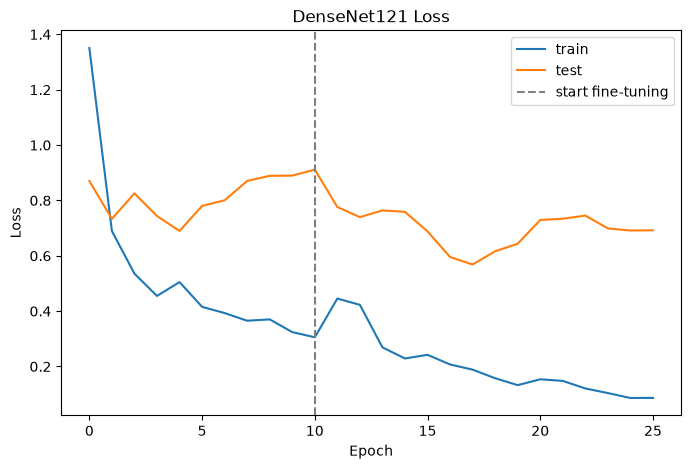

In [18]:
loss = history_stage1.history["loss"] + history_stage2.history["loss"]
val_loss = history_stage1.history["val_loss"] + history_stage2.history["val_loss"]

plt.figure(figsize=(8, 5))
plt.plot(loss, label="train")
plt.plot(val_loss, label="test")
plt.axvline(x=stage1_len - 1, color="gray", linestyle="--", label="start fine-tuning")
plt.title("DenseNet121 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()